https://www.kaggle.com/code/darshan1504/exploring-diffusion-models-with-jax

In [16]:
import numpy as np
import tensorflow as tf
# from keras.datasets.cifar10 import load_data
from keras.datasets.mnist import load_data
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Layer
import math

from matplotlib import pyplot as plt

In [ ]:
(x_train, y_train), (x_test, y_test) = load_data()
# x_train = (x_train.astype("float32") - 127.5) / 127.5

(60000, 32, 32, 1)


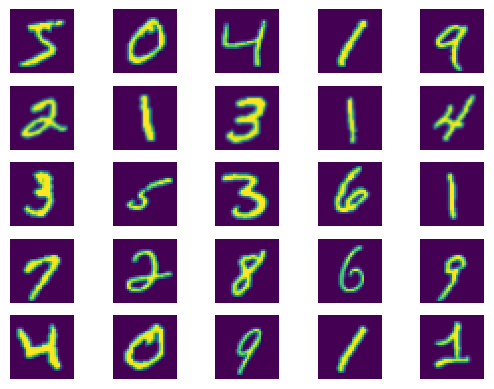

In [18]:
x_train = np.expand_dims(x_train, axis=-1) 
# x_train = (x_train.astype("float32") - 127.5) / 127.5

x_train = tf.image.resize(tf.cast(x_train, tf.float32) / 127.5 - 1, (32, 32))
print(x_train.shape)

# plot 25 images
for i in range(25):
	plt.subplot(5, 5, 1 + i)
	plt.axis('off')
	plt.imshow(x_train[i])
plt.show()

In [19]:
IMAGE_SIZE = x_train.shape[1:]
BATCH_SIZE = 256
CHANNELS = x_train.shape[3]
EPOCHS = 30
TIMESTEPS = 200
LEARNING_RATE = 1e-4
FILE_NAME = "mnist.weights.h5"
IS_TRAINING = False

print(IMAGE_SIZE, BATCH_SIZE, CHANNELS, EPOCHS, TIMESTEPS, LEARNING_RATE, FILE_NAME)

(32, 32, 1) 256 1 30 200 0.0001 mnist.weights.h5


$$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 + \alpha_t} \epsilon$$

$$noisy \space image = \sqrt{\bar{\alpha}_t} \times image + \sqrt{1- \bar{\alpha}_t} \times noise$$

(32, 32, 1)


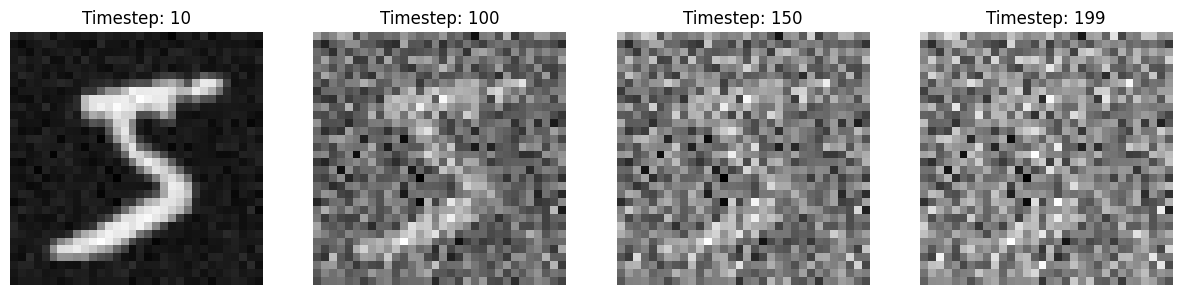

In [20]:
# create a fixed linear beta schedule
beta_start = 0.0001
beta_end = 0.02
beta = np.linspace(beta_start, beta_end, TIMESTEPS)

alpha = 1 - beta
alpha_bar = np.cumprod(alpha, axis=0)
alpha_bar = np.concatenate((np.array([1.]), alpha_bar[:-1]), axis=0)
sqrt_alpha_bar = np.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = np.sqrt(1-alpha_bar)

# this function will help us set the RNG key for Numpy
def set_key(key):
    np.random.seed(key)

# this function will add noise to the input as per the given timestamp
def forward_noise(key, x_0, t):
    set_key(key)
    noise = np.random.normal(key, size=x_0.shape)
    reshaped_sqrt_alpha_bar_t = np.reshape(np.take(sqrt_alpha_bar, t), (-1, 1, 1, 1))
    reshaped_sqrt_one_minus_alpha_bar_t = np.reshape(np.take(sqrt_one_minus_alpha_bar, t), (-1, 1, 1, 1))

    # Applying the actual formula
    noisy_image = reshaped_sqrt_alpha_bar_t  * x_0 + reshaped_sqrt_one_minus_alpha_bar_t  * noise
    return noisy_image, noise

# this function will be used to create sample timestamps between 0 &amp; T
def generate_timestamp(key, num):
    set_key(key)
    return tf.random.uniform(shape=[num], minval=0, maxval=TIMESTEPS, dtype=tf.int32)

def demo():
    fig = plt.figure(figsize=(15, 5)) # Adjusted figure size for better view
    sample_img = x_train[0] # Shape (32, 32, 3)
    print(sample_img.shape)
    sample_batch = np.expand_dims(sample_img, 0)
    timesteps_to_show = [10, 100, 150, 199] # Showing 0 to see original

    for index, i in enumerate(timesteps_to_show):
        noisy_im, noise = forward_noise(0, sample_img, np.array([i,]))

        image_to_show = np.squeeze(noisy_im, -1)
        image_to_show = np.squeeze(image_to_show, 0)

        plt.subplot(1, len(timesteps_to_show), index+1)
        plt.title(f"Timestep: {i}")

        plt.imshow(image_to_show, cmap='gray')
        plt.axis('off')

    plt.show()

demo()

In [21]:
class SinusoidalPosEmb(Layer):
    def __init__(self, dim=32, max_positions=10000):
        super(SinusoidalPosEmb, self).__init__()
        self.dim = dim
        self.max_positions = max_positions

    def call(self, x, training=True):
        x = tf.cast(x, tf.float32)
        half_dim = self.dim // 2

        emb = math.log(self.max_positions) / (half_dim - 1)
        emb = tf.exp(tf.range(half_dim, dtype=tf.float32) * -emb)
        emb = x[:, None] * emb[None, :]
        emb = tf.concat([tf.sin(emb), tf.cos(emb)], axis=-1)

        return emb

class TimeEmbedding(Layer):
    def __init__(self, dim=32, **kwargs):
        super(TimeEmbedding, self).__init__(**kwargs)
        self.dim = dim
        self.time_emb = 4*dim

        self.emb = SinusoidalPosEmb(dim)
        self.dense1 = layers.Dense(self.time_emb)
        self.act = layers.Activation("swish")
        self.dense2 = layers.Dense(self.time_emb)

    def call(self, x, training=True):
        x = self.emb(x)
        x = self.dense1(x)
        x = self.act(x)
        x = self.dense2(x)
        return x

class Attention(Layer):
    def __init__(self, dim, num_heads=8, **kwargs):
        super(Attention, self).__init__(**kwargs)
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads 
        
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=self.head_dim)

    def call(self, x):
        batch_size = tf.shape(x)[0]
        h, w = x.shape[1], x.shape[2]
        
        flat_x = tf.reshape(x, (batch_size, h*w, self.dim))
        attn_x = self.mha(flat_x, flat_x)
        
        out_x = tf.reshape(attn_x, (batch_size, h, w, self.dim))
        return out_x

class Block(Layer):
    def __init__(self, dim=32, **kwargs):
        super(Block, self).__init__(**kwargs)
        self.conv = layers.Conv2D(dim, (3,3), padding="same")
        self.norm = layers.GroupNormalization(groups=8)
        self.act = layers.Activation("swish")
    
    def call(self, x, training=True):
        x = self.conv(x)
        x = self.norm(x)
        x = self.act(x)
        return x

class ResNetBlock(layers.Layer):
    def __init__(self, out_channels=32, **kwargs):
        super(ResNetBlock, self).__init__(**kwargs)
        self.out_channels = out_channels
        
        # --- BLOCK 1 ---
        self.conv_block1 = Block(out_channels)

        # --- TIME PROCESSING ---
        # Takes the time vector and formats it to match the image channels
        self.time_dense = layers.Dense(out_channels)
        self.time_act = layers.Activation("swish")

        # --- BLOCK 2 ---
        self.conv_block2 = Block(out_channels)

        # --- RESIDUAL MATCHING ---
        # A 1x1 Conv to ensure input shape matches output shape for adding
        self.res_conv = layers.Conv2D(out_channels, 1, padding="same")

    def call(self, x, t_emb=None):
        # 1. Save input for later (Residual connection)
        input_x = x
        
        # 2. First Convolution Block
        h = self.conv_block1(input_x)

        # 3. Inject Time (CRITICAL STEP)
        if t_emb is not None:
            # Process time
            t = tf.squeeze(t_emb, axis=1)
            t = self.time_act(t)
            t = self.time_dense(t)
            # Reshape time to (Batch, 1, 1, Channels) so it broadcasts over the image
            t = tf.expand_dims(tf.expand_dims(t, 1), 1)
            # Add time to the image features
            h = h + t

        # 4. Second Convolution Block
        h = self.conv_block2(h)

        # 5. Residual Connection
        # We transform the original input to match the output channels
        residual = self.res_conv(input_x)
        
        # Return: Original(transformed) + New Learned Features
        return h + residual


In [22]:
def build_unet(img_size):
    dim = 32
    dim_scale_factor = (1, 2, 4, 8)
    num_groups = 8
    channels = CHANNELS

    image_input = layers.Input(shape=(img_size, img_size, channels), name="image_input")
    time_input = layers.Input(shape=(1,), name="time_input")

    t_emb = TimeEmbedding(dim)(time_input)

    x = layers.Conv2D(dim // 3 * 2, kernel_size=7, padding="same")(image_input)

    skips = [] # List to store the "sketches" for the skip connections
    dims = [dim * i for i in dim_scale_factor] # e.g., [32, 64, 128, 256]

    # ==========================================
    # 3. Downsampling Path (Left Side)
    # ==========================================
    for index, current_dim in enumerate(dims):
        # --- A. ResNet Blocks with Time Injection ---
        x = ResNetBlock(current_dim)(x, t_emb)
        x = ResNetBlock(current_dim)(x, t_emb)

        attn = Attention(current_dim)(x)
        norm = layers.GroupNormalization(groups=num_groups)(attn)
        x = norm + x

        skips.append(x)

        if index != len(dims) - 1:
            x = layers.Conv2D(current_dim, kernel_size=4, strides=2, padding="same")(x)

    # ==========================================
    # 4. Middle Block (Bottleneck)
    # ==========================================
    mid_dim = dims[-1]
    x = ResNetBlock(mid_dim)(x, t_emb)
    attn = Attention(mid_dim)(x)
    norm = layers.GroupNormalization(groups=num_groups)(attn)
    x = norm + x
    x = ResNetBlock(mid_dim)(x, t_emb)

    # ==========================================
    # 5. Upsampling Path (Right Side)
    # ==========================================
    for index, current_dim in enumerate(reversed(dims)):
        skip_layer = skips.pop() 
        x = layers.Concatenate()([skip_layer, x])

        x = ResNetBlock(current_dim)(x, t_emb)
        x = ResNetBlock(current_dim)(x, t_emb)

        attn = Attention(current_dim)(x)
        norm = layers.GroupNormalization(groups=num_groups)(attn)
        x = norm + x

        if index != len(dims) - 1:
            x = layers.Conv2DTranspose(current_dim, kernel_size=4, strides=2, padding="same")(x)

    # ==========================================
    # 6. Final Output
    # ==========================================
    x = ResNetBlock(dim)(x, t_emb)
    output = layers.Conv2D(channels, kernel_size=1, padding="same")(x)

    # Create the Model
    return models.Model(inputs=[image_input, time_input], outputs=output, name="UNet")

# ==========================================
# How to use it
# ==========================================
model = build_unet(img_size=x_train.shape[1])
model.summary()
optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
loss_fn = tf.keras.losses.MeanSquaredError()

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 32, 32, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_62 (Conv2D)  │ (None, 32, 32,    │      1,000 │ image_input[0][0] │
│                     │ 20)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_embedding_1    │ (None, 1, 128)    │     20,736 │ time_input[0][0]  │
│ (TimeEmbedding)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_19    │ (None, 32, 32,    │     19,968 │ conv2d_62[0][0],  │
│ (ResNetBlock)       │ 32)               │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_20    │ (None, 32, 32,    │     23,808 │ res_net_block_19… │
│ (ResNetBlock)       │ 32)               │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_9         │ (None, 32, 32,    │      4,224 │ res_net_block_20… │
│ (Attention)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 32, 32,    │         64 │ attention_9[0][0] │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 32, 32,    │          0 │ group_normalizat… │
│                     │ 32)               │            │ res_net_block_20… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_69 (Conv2D)  │ (None, 16, 16,    │     16,416 │ add_9[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_21    │ (None, 16, 16,    │     66,048 │ conv2d_69[0][0],  │
│ (ResNetBlock)       │ 64)               │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_22    │ (None, 16, 16,    │     86,528 │ res_net_block_21… │
│ (ResNetBlock)       │ 64)               │            │ time_embedding_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_10        │ (None, 16, 16,    │     16,640 │ res_net_block_22… │
│ (Attention)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        128 │ attention_10[0][… │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 16, 16,    │          0 │ group_normalizat… │
│                     │ 64)               │            │ res_net_block_22… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_76 (Conv2D)  │ (None, 8, 8, 64)  │     65,600 │ add_10[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_block_23    │ (None, 8, 8, 128) │    246,784 │ conv2d_76[0][0],  │
│ (ResNetBlock)       │                   │            │ time_embedding_1

 Total params: 12,820,009 (48.90 MB)

 Trainable params: 12,820,009 (48.90 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
@tf.function
def train_step(images):
    batch_size = tf.shape(images)[0]
    images = tf.cast(images, tf.float32)
    noise = tf.random.normal(tf.shape(images), dtype=tf.float32)

    # Generate random timesteps for each image in the batch
    t = tf.random.uniform((batch_size,), minval=0, maxval=TIMESTEPS, dtype=tf.int32)

    # Gather the correct alpha values for each timestep and reshape for broadcasting
    sqrt_alpha_prod_32 = tf.reshape(tf.gather(sqrt_alpha_bar, t), (-1, 1, 1, 1))
    sqrt_one_minus_alpha_prod_32 = tf.reshape(tf.gather(sqrt_one_minus_alpha_bar, t), (-1, 1, 1, 1))

    # Cast to float32
    sqrt_alpha_prod_32 = tf.cast(sqrt_alpha_prod_32, tf.float32)
    sqrt_one_minus_alpha_prod_32 = tf.cast(sqrt_one_minus_alpha_prod_32, tf.float32)

    noisy_images = sqrt_alpha_prod_32 * images + sqrt_one_minus_alpha_prod_32 * noise

    # Convert timestep to float and normalize for the model
    t_float = tf.cast(t, tf.float32) / tf.cast(TIMESTEPS, tf.float32)
    t_float = tf.reshape(t_float, (-1, 1))

    with tf.GradientTape() as tape:
        predicted_noise = model([noisy_images, t_float], training=True)
        loss = loss_fn(noise, predicted_noise)

    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

In [24]:
if IS_TRAINING:
    import time
    print("Starting Training...")
    # Create a proper batched dataset
    train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
    train_dataset = train_dataset.shuffle(buffer_size=10000).batch(BATCH_SIZE)

    for epoch in range(EPOCHS):
        start_time = time.time()
        epoch_loss = 0
        steps = 0
        batch_count = 0
        for batch_images in train_dataset:
            loss = train_step(batch_images)
            epoch_loss += loss
            steps += 1
            batch_count += 1
            if batch_count % 10 == 0:
                print(f"Batch {batch_count} - Loss: {loss:.4f}")

        print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {epoch_loss/steps:.4f}, time taken: {time.time()-start_time}")

In [25]:
if IS_TRAINING:
    model.save_weights(FILE_NAME)
    print("Model weights saved to", FILE_NAME)
else:
    model.load_weights(FILE_NAME)
    print("Model weights loaded from", FILE_NAME)

Model weights loaded from mnist.weights.h5


In [26]:
# create a fixed linear beta schedule
beta_start = 0.0001
beta_end = 0.02
beta = np.linspace(beta_start, beta_end, TIMESTEPS, dtype=np.float32)

alpha = 1 - beta
alpha_bar = np.cumprod(alpha, axis=0)
alpha_bar = np.concatenate((np.array([1.], dtype=np.float32), alpha_bar[:-1]), axis=0)
sqrt_alpha_bar = np.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = np.sqrt(1-alpha_bar)

  0%|          | 0/199 [00:00<?, ?it/s]

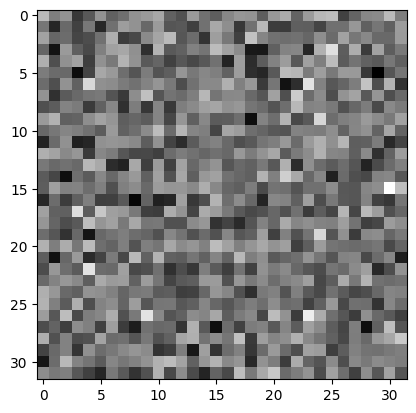

 13%|█▎        | 25/199 [00:06<00:39,  4.43it/s]

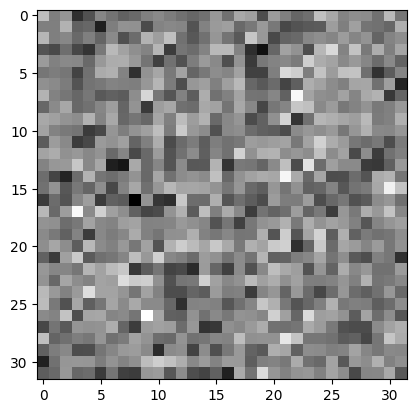

 25%|██▌       | 50/199 [00:11<00:31,  4.71it/s]

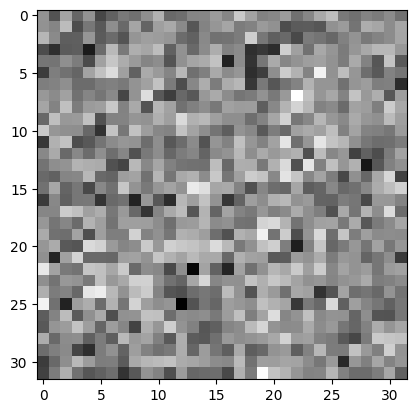

 38%|███▊      | 75/199 [00:16<00:26,  4.69it/s]

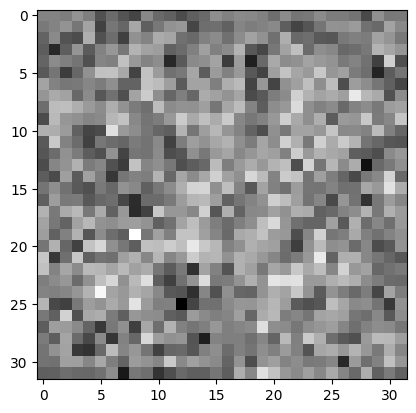

 50%|█████     | 100/199 [00:22<00:20,  4.74it/s]

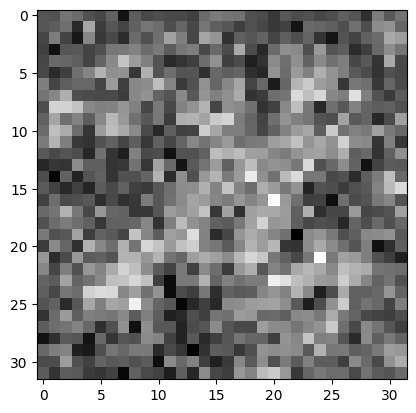

 63%|██████▎   | 125/199 [00:27<00:15,  4.71it/s]

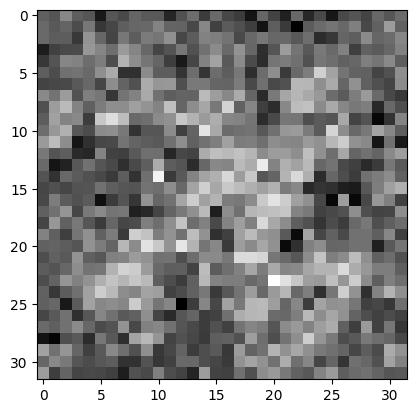

 75%|███████▌  | 150/199 [00:33<00:10,  4.75it/s]

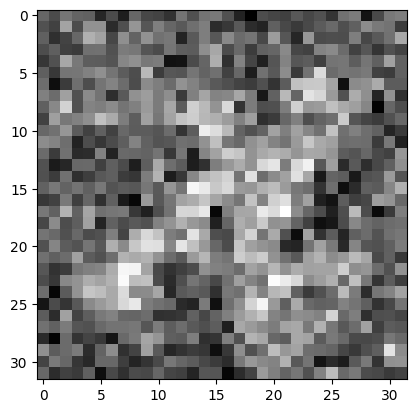

 88%|████████▊ | 175/199 [00:38<00:05,  4.75it/s]

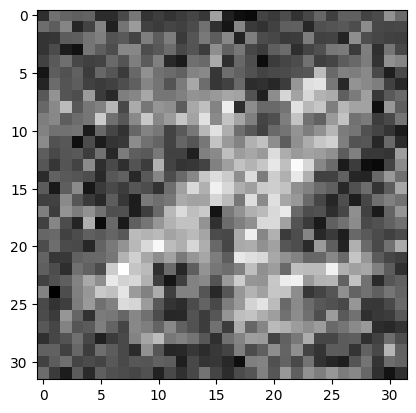

100%|██████████| 199/199 [00:43<00:00,  4.55it/s]


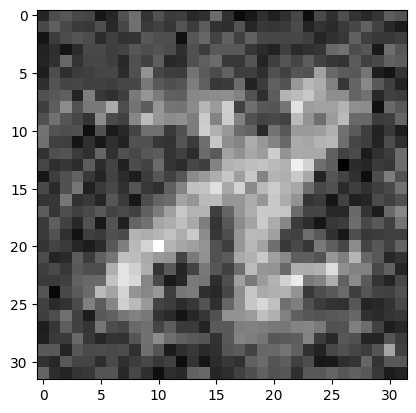

In [27]:
import random
from tqdm import tqdm

def backward_denoising_ddpm(x_t, pred_noise, t):
    alpha_t = tf.gather(alpha, t)
    alpha_t_bar = tf.gather(alpha_bar, t)

    eps_coef = (1 - alpha_t) / (1 - alpha_t_bar) ** .5  
    mean = 1 / (alpha_t ** 0.5) * (x_t - eps_coef * pred_noise)
    
    var = tf.gather(beta, t)
    z = tf.random.normal(tf.shape(x_t), dtype=tf.float32)

    return mean + (var ** 0.5) * z


# Generating Gaussian noise
x = tf.random.normal((1, 32, 32, 1), dtype=tf.float32, seed=random.randint(0, 1000))

# Create a list to store output images
img_list_ddpm = []

# Append the initial noise to the list of images
img_list_ddpm.append(tf.squeeze(tf.squeeze(x, 0),-1))

# Iterate over T timesteps
for i in tqdm(range(0, TIMESTEPS - 1)):
  # t-th timestep  
  t = tf.expand_dims(tf.constant(TIMESTEPS - i - 1, dtype=tf.int32), 0)
  
  # Predict noise using U-Net
  pred_noise = model([x, t])
  
  # Obtain the output from the noise using the formula seen before
  x = backward_denoising_ddpm(x, pred_noise, t)

  # Log the image after every 25 iterations
  if i % 25 == 0:
    img_list_ddpm.append(tf.squeeze(tf.squeeze(x, 0), -1))
    plt.imshow(tf.squeeze(tf.squeeze(x, 0), -1), cmap='gray')
    plt.show()

# Display the final generated image
plt.imshow(tf.squeeze(tf.squeeze(x, 0), -1), cmap='gray')
plt.show()


In [28]:
def backward_denoising_ddim(x_t, pred_noise, t, sigma_t):
  alpha_bar_t = tf.gather(alpha_bar, t)
  alpha_t_minus_one = tf.gather(alpha, t - 1)
    
  # predicted x_0
  pred = (x_t - ((1 - alpha_bar_t) ** 0.5) * pred_noise)/ (alpha_bar_t ** 0.5)
  pred = (alpha_t_minus_one ** 0.5) * pred
    
  # direction pointing to x_t
  pred = pred + ((1 - alpha_t_minus_one - (sigma_t ** 2)) ** 0.5) * pred_noise
  
  # random noise
  eps_t = tf.random.normal(tf.shape(x_t), dtype=tf.float32)
  pred = pred + (sigma_t * eps_t)
  
  return pred

  0%|          | 0/10 [00:00<?, ?it/s]

tf.Tensor([180], shape=(1,), dtype=int32)


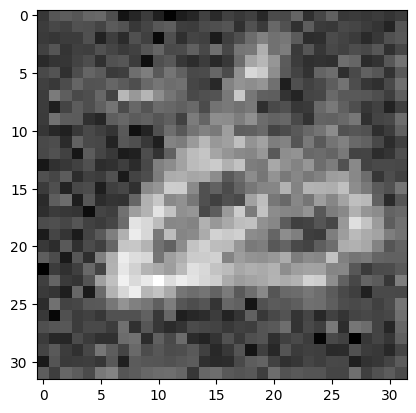

 10%|█         | 1/10 [00:00<00:02,  3.68it/s]

tf.Tensor([160], shape=(1,), dtype=int32)


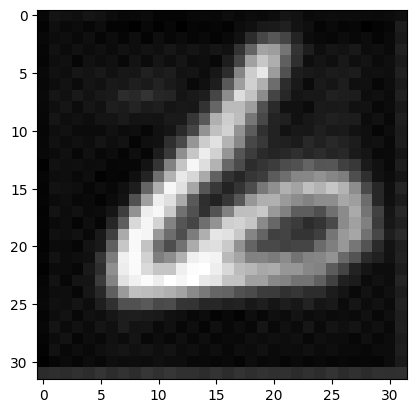

 20%|██        | 2/10 [00:00<00:02,  3.26it/s]

tf.Tensor([140], shape=(1,), dtype=int32)


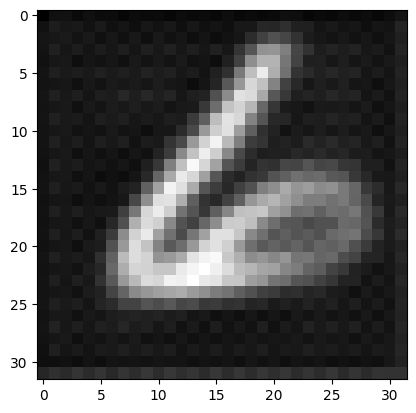

 30%|███       | 3/10 [00:00<00:02,  3.29it/s]

tf.Tensor([120], shape=(1,), dtype=int32)


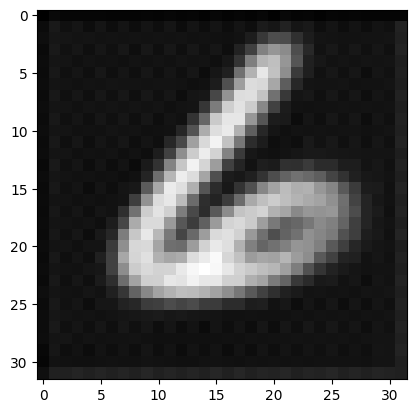

 40%|████      | 4/10 [00:01<00:01,  3.34it/s]

tf.Tensor([100], shape=(1,), dtype=int32)


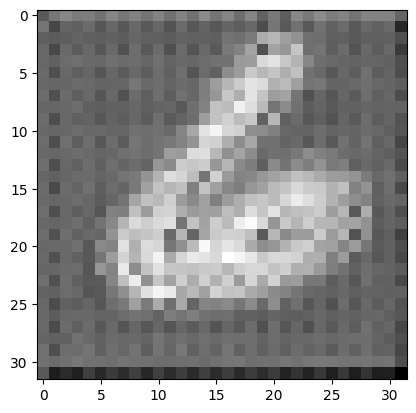

 50%|█████     | 5/10 [00:01<00:01,  3.31it/s]

tf.Tensor([80], shape=(1,), dtype=int32)


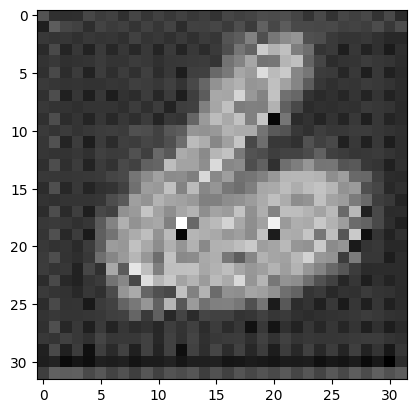

 60%|██████    | 6/10 [00:01<00:01,  3.38it/s]

tf.Tensor([60], shape=(1,), dtype=int32)


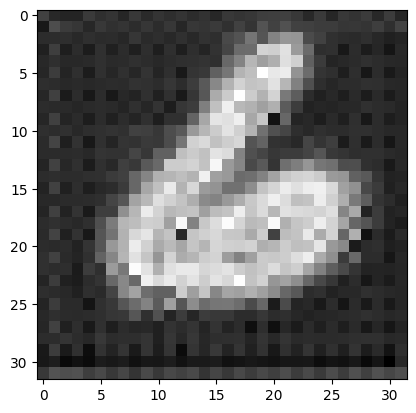

 70%|███████   | 7/10 [00:02<00:00,  3.42it/s]

tf.Tensor([40], shape=(1,), dtype=int32)


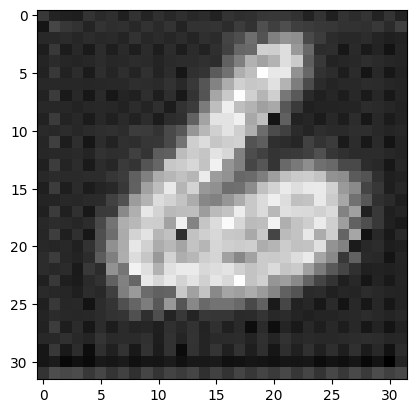

 80%|████████  | 8/10 [00:02<00:00,  3.43it/s]

tf.Tensor([20], shape=(1,), dtype=int32)


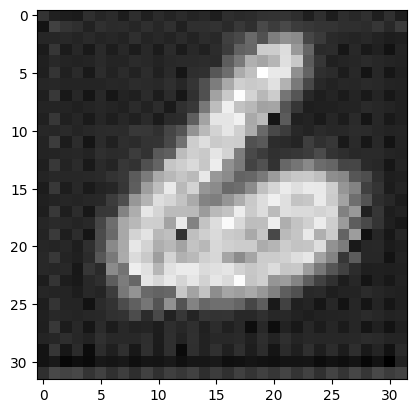

 90%|█████████ | 9/10 [00:02<00:00,  3.46it/s]

tf.Tensor([0], shape=(1,), dtype=int32)


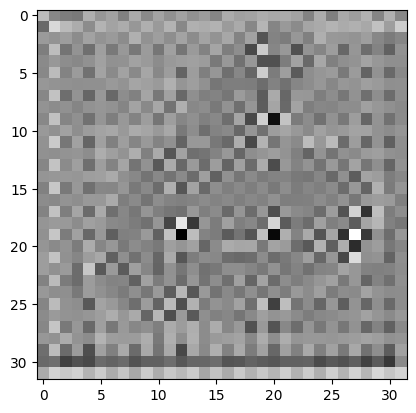

100%|██████████| 10/10 [00:02<00:00,  3.43it/s]


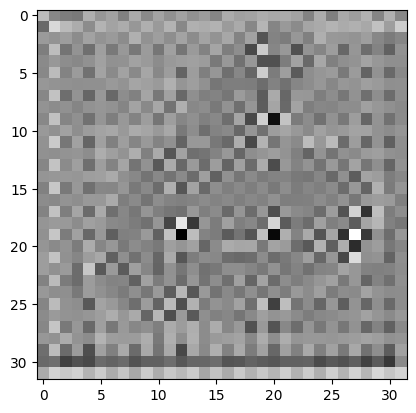

In [31]:
# Create a list to store output images
img_list_ddim = []

# Generate some noise
x = tf.random.normal((1, 32, 32, 1), dtype=tf.float32, seed=random.randint(0, 1000))

# Append noise to image list
img_list_ddim.append(tf.squeeze(tf.squeeze(x, 0),-1))

# Define number of inference loops to run
inference_timesteps = 10

# Create a range of inference steps that the output should be sampled at
inference_range = range(0, TIMESTEPS, TIMESTEPS // inference_timesteps)

# Iterate over inference_timesteps
for index, i in tqdm(enumerate(reversed(range(inference_timesteps))), total=inference_timesteps):
  
  # Fetch t for that specific timestep  
  t = tf.expand_dims(inference_range[i], 0) 
  print(t)
  
  # Predict the noise  
  pred_noise = model([x, t])
   
  # Obtain the output from the noise using the formula seen before
  x = backward_denoising_ddim(x, pred_noise, t, 0)

  # Log and display output image at every timestep
  if index % 1 == 0:
    plt.imshow(tf.squeeze(tf.squeeze(x, 0),-1), cmap='gray')
    plt.show()
    img_list_ddim.append(tf.squeeze(tf.squeeze(x, 0),-1))

# Display the final generated image
plt.imshow(tf.squeeze(tf.squeeze(x, 0),-1), cmap='gray')
plt.show()